In [5]:
"""
Local sensitivity analysis for Alloy 718 yield strength using a PCE surrogate.

This script uses ONLY the analytic gradient methodology (ChaosPy derivative of the PCE polynomial)
to compute local sensitivities dY/dx at a base composition, then estimates the expected strength
variation given user-specified wt.% perturbations.

Workflow:
  1) Load the trained PCE surrogate (pickled ChaosPy model)
  2) Compute analytic (PCE) gradient at a base composition
  3) Ask user for wt.% variations (ΔNi, ΔCr, ..., ΔMo) in the same order
  4) Compute per-element ΔY and the total expected ΔY
"""

from __future__ import annotations

import pickle
from pathlib import Path
from typing import Dict, Sequence, Tuple

import numpy as np
import matplotlib.pyplot as plt
import chaospy as cp

In [6]:
# ----------------------------
# Configuration
# ----------------------------
ELEMENTS: Tuple[str, ...] = ("Ni", "Cr", "Nb", "Al", "Ti", "Co", "Mo")
SURROGATE_MODEL_PATH = Path("C:/Users/hasan/OneDrive - andrew.cmu.edu/Thermo_Calc/Thermo_Calc_training/IN718/Strength/Baybe demo for strength/Data/pce_surrogate.pkl")


# ----------------------------
# Load surrogate model
# ----------------------------
if not SURROGATE_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Surrogate model file not found: {SURROGATE_MODEL_PATH.resolve()}\n"
        "Make sure you trained and saved the PCE model first."
    )

with open(SURROGATE_MODEL_PATH, "rb") as f:
    surrogate_model = pickle.load(f)


def surrogate_predict(X: np.ndarray) -> np.ndarray:
    """
    Predict yield strength (MPa) from compositions X of shape (N, 7) in wt%.
    Expected order: [Ni, Cr, Nb, Al, Ti, Co, Mo]
    """
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[1] != len(ELEMENTS):
        raise ValueError(f"X must have shape (N, {len(ELEMENTS)}). Got {X.shape}.")
    return surrogate_model(*X.T)

In [7]:
def pce_analytic_gradient(
    base_comp_wt: Sequence[float],
    pce_poly_model,
    elements: Tuple[str, ...] = ELEMENTS,
) -> Dict[str, float]:
    """
    Compute local partial derivatives dY/dx at base_comp_wt using ChaosPy analytic derivatives.
    Returns MPa per wt.% if the surrogate inputs are wt.%.
    """
    x = np.asarray(base_comp_wt, dtype=float)
    if x.shape[0] != len(elements):
        raise ValueError(f"base_comp_wt must have length {len(elements)} (got {x.shape[0]}).")

    grads = [float(cp.derivative(pce_poly_model, j)(*x)) for j in range(len(elements))]
    return dict(zip(elements, grads))


def expected_strength_variation_from_gradients(
    dYdx: Dict[str, float],
    delta_wt: Sequence[float],
    elements: Tuple[str, ...] = ELEMENTS,
    combine: str = "sum",
) -> Tuple[Dict[str, float], float]:
    """
    Compute per-element ΔY_i = (dY/dx_i) * Δx_i and a total (sum/abs/rss).
    """
    delta_wt = np.asarray(delta_wt, dtype=float)
    if delta_wt.shape[0] != len(elements):
        raise ValueError(f"delta_wt must have length {len(elements)} (got {delta_wt.shape[0]}).")

    per_element = {}
    contribs = []
    for el, dwt in zip(elements, delta_wt):
        if el not in dYdx:
            raise KeyError(f"Gradient dict missing element '{el}'. Keys={list(dYdx.keys())}")
        dy = float(dYdx[el] * dwt)
        per_element[el] = dy
        contribs.append(dy)

    contribs = np.asarray(contribs, dtype=float)

    if combine == "sum":
        total = float(np.sum(contribs))
    elif combine == "abs":
        total = float(np.sum(np.abs(contribs)))
    elif combine == "rss":
        total = float(np.sqrt(np.sum(contribs**2)))
    else:
        raise ValueError("combine must be one of: 'sum', 'abs', 'rss'")

    return per_element, total


def normalize_sensitivities_0_1(dYdx: Dict[str, float], elements: Tuple[str, ...] = ELEMENTS) -> Dict[str, float]:
    """
    Normalize |dY/dx| to [0, 1] for ranking/plotting.
    """
    vals = np.array([abs(float(dYdx[e])) for e in elements], dtype=float)
    vmax = float(np.max(vals)) if vals.size else 0.0
    if vmax <= 0.0:
        return {e: 0.0 for e in elements}
    normed = vals / vmax
    return {e: float(v) for e, v in zip(elements, normed)}


Enter base composition in wt.% (order: Ni, Cr, Nb, Al, Ti, Co, Mo).

Enter expected variation in each element (wt.%).
Use signed values if you want signed ΔY; set absolute=True to treat as magnitudes.

Base composition: {'Ni': 52.0, 'Cr': 19.0, 'Nb': 5.0, 'Al': 0.5, 'Ti': 1.0, 'Co': 0.5, 'Mo': 3.2}
Variations: {'Ni': 0.1, 'Cr': 0.1, 'Nb': 0.05, 'Al': 0.05, 'Ti': -0.05, 'Co': 0.05, 'Mo': 0.1}


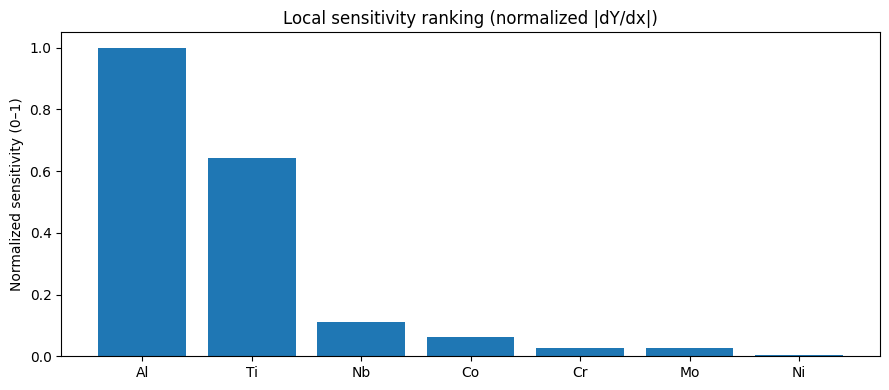

Raw local gradients dY/dx (MPa per wt.%):
  Ni:  2.878874
  Cr:  19.369584
  Nb:  78.096741
  Al:  699.138653
  Ti:  448.346524
  Co:  43.663154
  Mo:  19.337193

Expected per-element strength change ΔY (MPa):
  Ni:  0.288
  Cr:  1.937
  Nb:  3.905
  Al:  34.957
  Ti: -22.417
  Co:  2.183
  Mo:  1.934

Total expected strength change ΔY_total (MPa) [sum]:  22.786


In [11]:
def prompt_base_composition(elements: Tuple[str, ...] = ELEMENTS) -> np.ndarray:
    print("Enter base composition in wt.% (order: Ni, Cr, Nb, Al, Ti, Co, Mo).")
    vals = []
    for el in elements:
        v = float(input(f"{el} (wt.%): ").strip())
        vals.append(v)
    return np.asarray(vals, dtype=float)


def prompt_element_variations(elements: Tuple[str, ...] = ELEMENTS, absolute: bool = False) -> np.ndarray:
    print("\nEnter expected variation in each element (wt.%).")
    print("Use signed values if you want signed ΔY; set absolute=True to treat as magnitudes.")
    vals = []
    for el in elements:
        v = float(input(f"Δ{el} (wt.%): ").strip())
        vals.append(abs(v) if absolute else v)
    return np.asarray(vals, dtype=float)


theta = prompt_base_composition(ELEMENTS)
delta = prompt_element_variations(ELEMENTS, absolute=False)

print("\nBase composition:", dict(zip(ELEMENTS, theta)))
print("Variations:", dict(zip(ELEMENTS, delta)))

# 1) PCE analytic gradients
dYdx = pce_analytic_gradient(theta, surrogate_model, elements=ELEMENTS)

# 2) Normalize sensitivities for ranking plot (0–1)
sens01 = normalize_sensitivities_0_1(dYdx, elements=ELEMENTS)

# Sort by normalized sensitivity descending
sorted_elements = sorted(ELEMENTS, key=lambda e: sens01[e], reverse=True)
sorted_scores = [sens01[e] for e in sorted_elements]

# Plot sensitivity ranking (0–1)
plt.figure(figsize=(9, 4))
plt.bar(sorted_elements, sorted_scores)
plt.ylim(0, 1.05)
plt.ylabel("Normalized sensitivity (0–1)")
plt.title("Local sensitivity ranking (normalized |dY/dx|)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Raw local gradients dY/dx (MPa per wt.%):")
for el in ELEMENTS:
    print(f"  {el}: {dYdx[el]: .6f}")

# 3) Expected strength variation from user input variations
per_el_dY, total_dY = expected_strength_variation_from_gradients(
    dYdx=dYdx,
    delta_wt=delta,
    elements=ELEMENTS,
    combine="sum",   # change to "abs" or "rss" if you want
)

print("\nExpected per-element strength change ΔY (MPa):")
for el in ELEMENTS:
    print(f"  {el}: {per_el_dY[el]: .3f}")

print(f"\nTotal expected strength change ΔY_total (MPa) [sum]: {total_dY: .3f}")

In [12]:
import pandas as pd
rank_df = (
    pd.DataFrame({
        "Element": list(ELEMENTS),
        "dY/dx (MPa/wt.%)": [dYdx[e] for e in ELEMENTS],
        "|dY/dx|": [abs(dYdx[e]) for e in ELEMENTS],
        "Normalized (0–1)": [sens01[e] for e in ELEMENTS],
        "Δwt.%": [delta[i] for i in range(len(ELEMENTS))],
        "ΔY (MPa)": [per_el_dY[e] for e in ELEMENTS],
    })
    .sort_values("Normalized (0–1)", ascending=False)
    .reset_index(drop=True)
)

rank_df


,Element,dY/dx (MPa/wt.%),|dY/dx|,Normalized (0–1),Δwt.%,ΔY (MPa)
0,Al,699.138653,699.138653,1.000000,0.05,34.956933
1,Ti,448.346524,448.346524,0.641284,-0.05,-22.417326
2,Nb,78.096741,78.096741,0.111704,0.05,3.904837
3,Co,43.663154,43.663154,0.062453,0.05,2.183158
4,Cr,19.369584,19.369584,0.027705,0.10,1.936958
5,Mo,19.337193,19.337193,0.027659,0.10,1.933719
6,Ni,2.878874,2.878874,0.004118,0.10,0.287887
